# R-GCN enrichment ablation on the F1 KGs

Which SULO enrichments make Hybrid differ from Ad-hoc, and what does each one contribute to node
prediction (`RaceEntry` → `hasRacePoints`)? Comparing the two schemas gives five units, each ablated
on its own (`f1_node_data.ABLATION_UNITS`):

| Unit | Hybrid | Ad-hoc |
|---|---|---|
| `sulo_typing` | instances also typed with their SULO superclass (`sulo:Process`, `sulo:SpatialObject`, ...) | domain class only |
| `precedesRace` | `Race sulo:precedes Race` | absent |
| `precedesSeason` | `Season sulo:precedes Season` (same predicate as `precedesRace`) | absent |
| `hasTeamMember` | `Team sulo:hasItem Driver` | absent |
| `rank_reification` | `Position/<n> sulo:isReferredToIn Position/<n>/hasRank sulo:hasValue <rank>` | `Position/<n> hasRank <rank>` |

`heldAtCircuit` → `isInCircuit` is not a unit: it renames the predicate and leaves the edges unchanged
(`tests/test_f1_node_data.py` shows that Hybrid minus all five units is Ad-hoc up to that rename).

Each unit is ablated in both directions: **leave-one-out** (Hybrid − unit, compared with Hybrid) and
**add-one-in** (Ad-hoc + unit, compared with Ad-hoc). That gives 12 graphs, including the two
controls. A variant is a different schema, built with `f1_node_data.swap_units`, and rendered from the
same assertions with the same leakage mask and split, so it differs from its control only in the
unit's triples.

Every variant is trained with the **Hybrid winner's configuration** from `R-GCN`'s tuning run
(the same configuration for all 12 graphs, so only the graph changes). Each seed in `FINAL_SEEDS`
trains on train with early stopping on val, and the best-val weights are scored on test. This protocol
differs from the main notebooks' train+val retrain, so the controls are re-run here and the main
results are not compared with these. Limitation: the configuration was tuned on Hybrid, so it may
suit Hybrid-like graphs slightly better. That would bias leave-one-out deltas slightly negative and
add-one-in deltas slightly positive. This notebook and its GraphSAGE counterpart differ only in the model.

In [1]:
# Must run before CUDA is initialised: avoids fragmentation OOMs across a long sweep.
import os
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "f1_population.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from f1_node_data import (
    ABLATION_UNITS, ABLATION_VARIANTS, ablation_schema, build_kg_data, load_population,
    race_entry_labels, stratified_split,
)
from f1_population import SCHEMA_FILES, read_schema
from node_prediction.gnn_tools import (
    cleanup, evaluate_test_set, limit_cuda_memory_to_free_vram, run_ablation_variant, set_seed,
    summarize_ablation, train_model,
)
from node_prediction.models import RGCNModel

TUNING_CSV = ROOT / "outputs" / "f1" / "node_prediction" / "rgcn" / "hybrid_sulo_sequential_tuning_results.csv"
OUT_DIR = ROOT / "outputs" / "f1" / "node_prediction" / "ablation" / "rgcn"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print(torch.__version__, "| CUDA:", torch.cuda.is_available())
# WSL2 would otherwise overcommit VRAM into RAM and fail with a driver error instead of an OOM,
# which the run could not skip.
if torch.cuda.is_available():
    print(f"CUDA memory cap: {limit_cuda_memory_to_free_vram() / 2**30:.2f} GiB")

/home/domin/miniconda3/envs/sulo/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2.7.0+cu126 | CUDA: True
CUDA memory cap: 10.48 GiB


## Data

Each variant is rendered from `data/f1/assertions.csv` with its own schema, **without** the label and the
race outcomes (`build_kg_data`, same as the main notebooks). The split is computed once on IRIs and
shared by all variants. The table shows each variant's size and how it differs from its control.

In [2]:
entities, assertions = load_population(ROOT / "data" / "f1")
labels = race_entry_labels(assertions)
split = stratified_split(labels, seed=42)
schemas = {kg: read_schema(str(ROOT / path)) for kg, path in SCHEMA_FILES.items()}

kg_data = {
    variant: build_kg_data(base, entities, assertions, split, ablation_schema(variant, schemas))
    for variant, (base, _, _) in ABLATION_VARIANTS.items()
}
controls = {variant: base for variant, (base, _, _) in ABLATION_VARIANTS.items()}

stats = pd.DataFrame({
    variant: {
        "control": controls[variant],
        "nodes": d.data.num_nodes,
        "edges (fwd + inv)": d.data.edge_index.size(1),
        "relation types (fwd + inv)": d.num_relations,
        "feature keys": len(d.vocabulary),
    }
    for variant, d in kg_data.items()
}).T
for col in ["nodes", "edges (fwd + inv)", "relation types (fwd + inv)"]:
    stats[f"Δ {col}"] = stats[col].values - stats.loc[stats["control"], col].values
stats

,control,nodes,edges (fwd + inv),relation types (fwd + inv),feature keys,Δ nodes,Δ edges (fwd + inv),Δ relation types (fwd + inv)
hybrid_sulo,hybrid_sulo,57985,525162,58,1260,0,0,0
adhoc,adhoc,57946,432642,52,1254,0,0,0
hybrid_minus_sulo_typing,hybrid_sulo,57981,438964,58,1256,-4,-86198,0
hybrid_minus_precedesRace,hybrid_sulo,57985,523010,58,1260,0,-2152,0
hybrid_minus_precedesSeason,hybrid_sulo,57985,525010,58,1260,0,-152,0
hybrid_minus_hasTeamMember,hybrid_sulo,57985,521280,56,1260,0,-3882,-2
hybrid_minus_rank_reification,hybrid_sulo,57951,525026,56,1259,-34,-136,-2
adhoc_plus_sulo_typing,adhoc,57951,518840,52,1259,5,86198,0
adhoc_plus_precedesRace,adhoc,57946,434794,54,1254,0,2152,2
adhoc_plus_precedesSeason,adhoc,57946,432794,54,1254,0,152,2


## Constants

The training constants are the main notebook's, with the same sources. The architecture and optimiser
come from the Hybrid winner of `R-GCN`'s tuning run, read from its CSV, not hardcoded.
R-GCN keeps the Hybrid winner's basis count for every variant; it is at most each variant's relation count R.

In [3]:
# Full-batch, so one epoch = one gradient step. Max epochs 400 = the top of GraphGym's design space
# {100, 200, 400} (You et al. 2020, Section 4); Kipf & Welling 2017 cap at 200. Patience 50: no
# literature value (user choice, 2026-10-21). Same values as the main notebooks.
#   https://arxiv.org/abs/2011.08843
#   https://arxiv.org/abs/1609.02907
EPOCHS = 400
PATIENCE = 50

# Early-stopping warm-up (user, 2026-10-29): epochs 0-49 are trained but neither checkpointed nor counted
# towards patience, as Keras' EarlyStopping(start_from_epoch). In the first ablation run, 7 R-GCN seeds and
# 1 GraphSAGE seed kept a val spike from the unstable first ~15 epochs (best epoch 3-20) as the score to
# beat and stopped before passing it, ~0.02 test ROC-AUC below the other seeds; every other seed peaked
# after epoch 176. 50 is a user choice with no literature value. Ablation only: the main notebooks do not
# use it, so their train+val retrain is unchanged.
#   https://keras.io/api/callbacks/early_stopping/
START_FROM_EPOCH = 50

# Node input embedding size: the GraphSAGE reference implementation recommends learned identity
# features of 64-256 dims (README, --identity_dim).
#   https://github.com/williamleif/GraphSAGE#readme
FEATURE_DIM = 256

# Dropout: PyG's R-GCN example uses p=0.2 between the RGCNConv layers; the original
# R-GCN paper uses no dropout for entity classification.
#   https://github.com/pyg-team/pytorch_geometric/blob/master/examples/rgcn_link_pred.py
DROPOUT = 0.2

# The main notebooks' final-evaluation seeds (user, 2026-10-20); results are mean ± std over them.
FINAL_SEEDS = [0, 1, 2, 3, 4]

# Fixed configuration: the Hybrid winner (one phase-4 row per final seed, all with the same config).
winners = pd.read_csv(TUNING_CSV).query("phase == '4_Final_Test_Evaluation'")
config_columns = ["hidden_dim", "layers", "num_bases", "lr", "weight_decay"]
assert len(winners.drop_duplicates(config_columns)) == 1, "phase-4 rows disagree on the configuration"
winner = winners.iloc[0]
DEPTH = int(winner["layers"])
HIDDEN = [int(winner["hidden_dim"])] * (DEPTH - 1)
BASES = None if pd.isna(winner["num_bases"]) else int(winner["num_bases"])
assert BASES is None or all(BASES <= d.num_relations for d in kg_data.values()), "bases > R in a variant"
LR, WD = float(winner["lr"]), float(winner["weight_decay"])
print(f"Hybrid winner: hidden {HIDDEN}, layers {DEPTH}, bases {BASES}, lr {LR}, wd {WD}")

Hybrid winner: hidden [64, 64], layers 3, bases 10, lr 0.01, wd 0.0001


In [4]:
def model_factory(d):
    """(hidden_list, bases) -> fresh model for one variant; everything variant-specific is bound here."""
    def build(hidden_list, bases):
        return RGCNModel(
            num_keys=len(d.vocabulary), feature_dim=FEATURE_DIM, hidden_channels_list=hidden_list,
            num_relations=d.num_relations, num_bases=bases, dropout=DROPOUT,
        )
    return build

## Pipeline check: shuffled labels

Trains the fixed configuration on every variant with the labels permuted across all labelled
entries. The test ROC-AUC must stay at chance (≈ 0.5): otherwise the target vector reaches the
model's inputs somewhere in the variant's pipeline. The unit tests check, on the miniature tables,
that every variant keeps the mask and the split.

In [5]:
control_auc = {}
for variant, d in kg_data.items():
    labelled = torch.cat([d.train, d.val, d.test])
    shuffled = d.data.clone()
    shuffled.y[labelled] = d.data.y[labelled][torch.randperm(len(labelled), generator=torch.Generator().manual_seed(0))]

    set_seed(FINAL_SEEDS[0])
    model = model_factory(d)(HIDDEN, BASES)
    model, _ = train_model(model, shuffled, d.train, d.val, epochs=EPOCHS, lr=LR, weight_decay=WD,
                           patience=PATIENCE, start_from_epoch=START_FROM_EPOCH)
    control_auc[variant] = evaluate_test_set(model, shuffled, d.test)["roc_auc"]
    model.cpu()
    del model, shuffled
    cleanup()

pd.Series(control_auc, name="shuffled-label test ROC-AUC").round(4)

Epoch 000 | Train Loss: 1.1260 | Val Loss: 9.8798 | Val Acc: 0.3008 | Val F1: 0.4625 | Val ROC-AUC: 0.4903 | Grad Norm: 2.0577
Epoch 001 | Train Loss: 9.5906 | Val Loss: 7.5643 | Val Acc: 0.6992 | Val F1: 0.0000 | Val ROC-AUC: 0.4963 | Grad Norm: 33.4491
Epoch 002 | Train Loss: 7.8529 | Val Loss: 3.6717 | Val Acc: 0.6992 | Val F1: 0.0000 | Val ROC-AUC: 0.4968 | Grad Norm: 18.1091
Epoch 003 | Train Loss: 4.1733 | Val Loss: 3.2850 | Val Acc: 0.3008 | Val F1: 0.4625 | Val ROC-AUC: 0.4889 | Grad Norm: 15.8145
Epoch 004 | Train Loss: 2.9309 | Val Loss: 0.7353 | Val Acc: 0.6952 | Val F1: 0.0096 | Val ROC-AUC: 0.4918 | Grad Norm: 26.6107
Epoch 005 | Train Loss: 0.9878 | Val Loss: 1.6328 | Val Acc: 0.6992 | Val F1: 0.0000 | Val ROC-AUC: 0.4995 | Grad Norm: 1.6891
Epoch 006 | Train Loss: 1.5190 | Val Loss: 1.0596 | Val Acc: 0.6992 | Val F1: 0.0000 | Val ROC-AUC: 0.5005 | Grad Norm: 11.4995
Epoch 007 | Train Loss: 1.2868 | Val Loss: 0.9035 | Val Acc: 0.3119 | Val F1: 0.4606 | Val ROC-AUC: 0.5069

hybrid_sulo                      0.5034
adhoc                            0.4879
hybrid_minus_sulo_typing         0.4915
hybrid_minus_precedesRace        0.5027
hybrid_minus_precedesSeason      0.5207
hybrid_minus_hasTeamMember       0.4864
hybrid_minus_rank_reification    0.4825
adhoc_plus_sulo_typing           0.4799
adhoc_plus_precedesRace          0.4790
adhoc_plus_precedesSeason        0.4944
adhoc_plus_hasTeamMember         0.5052
adhoc_plus_rank_reification      0.5102
Name: shuffled-label test ROC-AUC, dtype: float64

## Ablation runs

Each of the 12 graphs is trained once per seed in `FINAL_SEEDS`. Rows are appended to
`ablation_results.csv` as each seed finishes: after a crash, finished (variant, seed) pairs are
skipped and failed ones are retried. Constants are not checked, so move the CSV away after changing one.

In [6]:
csv_path = OUT_DIR / "ablation_results.csv"
for variant, d in kg_data.items():
    results = run_ablation_variant(
        model_factory(d), d, variant, HIDDEN, BASES, LR, WD,
        epochs=EPOCHS, patience=PATIENCE, start_from_epoch=START_FROM_EPOCH, seeds=FINAL_SEEDS,
        save_dir=f"{OUT_DIR / 'checkpoints'}/", csv_path=csv_path,
    )
    cleanup()

results = pd.read_csv(csv_path)   # every variant's rows, including failed seeds of earlier variants
# An OOM-ed seed is logged, not fatal: every variant needs all its seeds to be compared.
failed = results[results["status"] != "ok"]
assert failed.empty, f"Ablation runs that did not finish:\n{failed[['variant', 'seed', 'status']]}"
assert len(results) == len(kg_data) * len(FINAL_SEEDS)
# Rows are resumed, not re-run: a row from before the warm-up with its best epoch inside it must be re-run.
early = results[results["best_epoch"] < START_FROM_EPOCH]
assert early.empty, f"Rows selected inside the warm-up (delete and re-run them):\n{early[['variant', 'seed', 'best_epoch']]}"


=== Ablation hybrid_sulo | seed 0 ===
Epoch 000 | Train Loss: 1.1229 | Val Loss: 8.9690 | Val Acc: 0.3178 | Val F1: 0.4770 | Val ROC-AUC: 0.6136 | Grad Norm: 3.3482
Epoch 001 | Train Loss: 8.9179 | Val Loss: 14.4088 | Val Acc: 0.6870 | Val F1: 0.0000 | Val ROC-AUC: 0.5778 | Grad Norm: 37.7527
Epoch 002 | Train Loss: 14.3386 | Val Loss: 8.2509 | Val Acc: 0.6870 | Val F1: 0.0000 | Val ROC-AUC: 0.5975 | Grad Norm: 25.9719
Epoch 003 | Train Loss: 8.4169 | Val Loss: 1.2599 | Val Acc: 0.6478 | Val F1: 0.4682 | Val ROC-AUC: 0.6186 | Grad Norm: 20.9978
Epoch 004 | Train Loss: 1.5885 | Val Loss: 7.1611 | Val Acc: 0.3130 | Val F1: 0.4768 | Val ROC-AUC: 0.6527 | Grad Norm: 4.5563
Epoch 005 | Train Loss: 6.8440 | Val Loss: 1.8849 | Val Acc: 0.3171 | Val F1: 0.4765 | Val ROC-AUC: 0.6640 | Grad Norm: 34.8836
Epoch 006 | Train Loss: 2.0612 | Val Loss: 2.2925 | Val Acc: 0.6870 | Val F1: 0.0000 | Val ROC-AUC: 0.6378 | Grad Norm: 19.9129
Epoch 007 | Train Loss: 2.7178 | Val Loss: 3.0455 | Val Acc: 0.68

## Results

Mean ± std over `FINAL_SEEDS` per variant, plus the difference between its mean and its control's
mean (`delta_*`): leave-one-out against Hybrid, add-one-in against Ad-hoc. A negative leave-one-out
delta means Hybrid loses something without the unit; a positive add-one-in delta means the unit
helps Ad-hoc on its own. Differences are reported as mean ± std, with no significance test (as in the main notebooks).

In [7]:
summary = summarize_ablation(results, controls)
summary.round(4).to_csv(OUT_DIR / "ablation_summary.csv")
summary.round(4)

,control,n_seeds,val_roc_auc_mean,val_roc_auc_std,test_roc_auc_mean,test_roc_auc_std,test_pr_auc_mean,test_pr_auc_std,test_f1_mean,test_f1_std,test_accuracy_mean,test_accuracy_std,delta_val_roc_auc,delta_test_roc_auc
variant,,,,,,,,,,,,,,
hybrid_sulo,hybrid_sulo,5,0.8397,0.0020,0.8690,0.0022,0.7423,0.0008,0.6732,0.0363,0.8047,0.0070,0.0000,0.0000
adhoc,adhoc,5,0.8398,0.0026,0.8692,0.0017,0.7428,0.0018,0.6676,0.0293,0.8027,0.0036,0.0000,0.0000
hybrid_minus_sulo_typing,hybrid_sulo,5,0.8395,0.0011,0.8690,0.0010,0.7428,0.0012,0.6764,0.0372,0.8022,0.0047,-0.0002,-0.0000
hybrid_minus_precedesRace,hybrid_sulo,5,0.8381,0.0012,0.8685,0.0012,0.7419,0.0029,0.6774,0.0227,0.8050,0.0025,-0.0016,-0.0005
hybrid_minus_precedesSeason,hybrid_sulo,5,0.8405,0.0006,0.8702,0.0006,0.7436,0.0019,0.6859,0.0207,0.8062,0.0030,0.0008,0.0012
hybrid_minus_hasTeamMember,hybrid_sulo,5,0.8400,0.0008,0.8700,0.0004,0.7434,0.0017,0.6921,0.0137,0.8048,0.0037,0.0004,0.0010
hybrid_minus_rank_reification,hybrid_sulo,5,0.8408,0.0010,0.8687,0.0019,0.7397,0.0026,0.6691,0.0214,0.8024,0.0036,0.0011,-0.0003
adhoc_plus_sulo_typing,adhoc,5,0.8416,0.0006,0.8690,0.0022,0.7404,0.0042,0.6906,0.0105,0.8070,0.0022,0.0018,-0.0002
adhoc_plus_precedesRace,adhoc,5,0.8406,0.0015,0.8700,0.0010,0.7423,0.0021,0.6633,0.0246,0.8033,0.0050,0.0007,0.0008


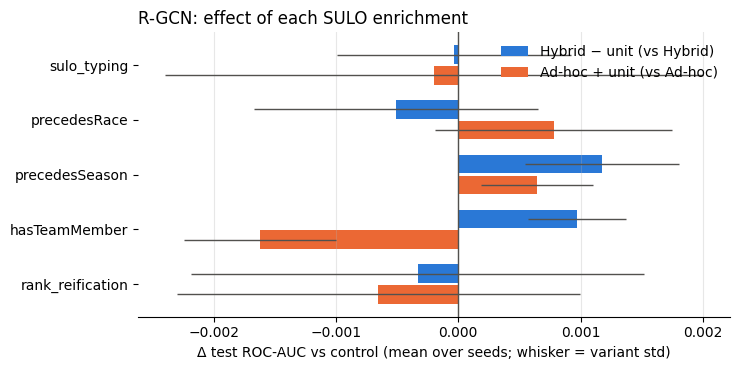

In [8]:
units = list(ABLATION_UNITS)
directions = [
    ("hybrid_minus", "Hybrid − unit (vs Hybrid)", "#2a78d6"),
    ("adhoc_plus", "Ad-hoc + unit (vs Ad-hoc)", "#eb6834"),
]
y = np.arange(len(units))
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for offset, (prefix, label, color) in zip((-0.19, 0.19), directions):
    rows = summary.loc[[f"{prefix}_{u}" for u in units]]
    ax.barh(y + offset, rows["delta_test_roc_auc"], height=0.34, color=color, label=label,
            xerr=rows["test_roc_auc_std"], error_kw=dict(elinewidth=1, ecolor="#52514e", capsize=0))
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_yticks(y, units)
ax.invert_yaxis()
ax.set_xlabel("Δ test ROC-AUC vs control (mean over seeds; whisker = variant std)")
ax.set_title("R-GCN: effect of each SULO enrichment", loc="left")
ax.grid(axis="x", alpha=0.3)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.legend(frameon=False, loc="best")
fig.tight_layout()
fig.savefig(OUT_DIR / "ablation_delta_test_roc_auc.png", dpi=200)
plt.show()

## Limitation: runs ended by the epoch cap

A seed whose best epoch is ≥ `EPOCHS − PATIENCE` was cut off by the `EPOCHS` cap while possibly still
improving, so its score may be understated (the same limitation as in the main notebooks).

In [9]:
results[results["best_epoch"] >= EPOCHS - PATIENCE][["variant", "seed", "best_epoch", "val_roc_auc", "test_roc_auc"]]

,variant,seed,best_epoch,val_roc_auc,test_roc_auc
11,hybrid_minus_sulo_typing,1,379,0.838622,0.868715
12,hybrid_minus_sulo_typing,2,365,0.838637,0.869532
14,hybrid_minus_sulo_typing,4,355,0.838893,0.867388
54,adhoc_plus_hasTeamMember,4,393,0.837918,0.867843
56,adhoc_plus_rank_reification,1,369,0.840805,0.869262
58,adhoc_plus_rank_reification,3,385,0.837009,0.865757
